# 01 · Inventory explorer — the 127 real documents

`outputs/` is a **listing inventory**, not a mirror: `tools/snapshot_inventory.py`
walked the listing pages captured from the five reachable portals on 2026-09-28
and wrote one manifest row per document it saw, with the name, size and date the
portal *published*. No payload was downloaded (every row has `status = dry_run`).

So the questions this notebook can answer are about **what the portals publish**:
how many documents, how big, what type, and when.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


In [2]:
inv = d.load_manifest("outputs")
print("documents:", len(inv), " sites:", inv["site"].nunique())
print("status values:", inv["status"].value_counts().to_dict())
print("captured on :", d.load_global("outputs").get("generated_at"))
display(inv.head(8)[["site", "name", "size", "remote_mtime", "status"]])

documents: 127  sites: 5
status values: {'dry_run': 127}
captured on : 2026-09-28T18:05:13Z


,site,name,size,remote_mtime,status
0,comissaodaverdade.al.sp.gov.br,001 - Ficha DEOPS Paulo Roberto Pinto BR_SPAPESP_DEOPSSPOSFTEXSNP0...,NaN,NaN,dry_run
1,comissaodaverdade.al.sp.gov.br,001 - Marco Antonio Braz Conversas com Mr[1].pdf,NaN,NaN,dry_run
2,comissaodaverdade.al.sp.gov.br,001-Antonio-Raymundo-Lucena.pdf,NaN,NaN,dry_run
3,comissaodaverdade.al.sp.gov.br,001-Antonio-Sergio-de-Mattos.pdf,NaN,NaN,dry_run
4,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,NaN,NaN,dry_run
5,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf,NaN,NaN,dry_run
6,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Jose-Maximino001.pdf,NaN,NaN,dry_run
7,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Jose-Maximino1001.pdf,NaN,NaN,dry_run


## 1 · How many documents does each portal publish?

In [3]:
per_site = (
    inv.groupby("site")
    .agg(
        documents=("url", "count"),
        with_size=("size", "count"),
        with_date=("mtime", "count"),
        total_bytes=("size", "sum"),
        median_bytes=("size", "median"),
        largest=("size", "max"),
    )
    .sort_values("documents", ascending=False)
)
per_site["total (human)"] = per_site["total_bytes"].map(d.human_bytes)
per_site["median (human)"] = per_site["median_bytes"].map(d.human_bytes)
per_site["largest (human)"] = per_site["largest"].map(d.human_bytes)
display(
    per_site[
        [
            "documents",
            "with_size",
            "with_date",
            "total (human)",
            "median (human)",
            "largest (human)",
        ]
    ]
)

,documents,with_size,with_date,total (human),median (human),largest (human)
site,,,,,,
valiprev.sp.gov.br,53,53,53,35.2 MiB,321.0 KiB,3.8 MiB
comissaodaverdade.al.sp.gov.br,42,0,0,0 B,-,-
dados.cvm.gov.br,18,18,18,170.2 MiB,9.5 MiB,13.0 MiB
macau.rn.gov.br,8,0,0,0 B,-,-
dadosabertos.pgfn.gov.br,6,0,0,0 B,-,-


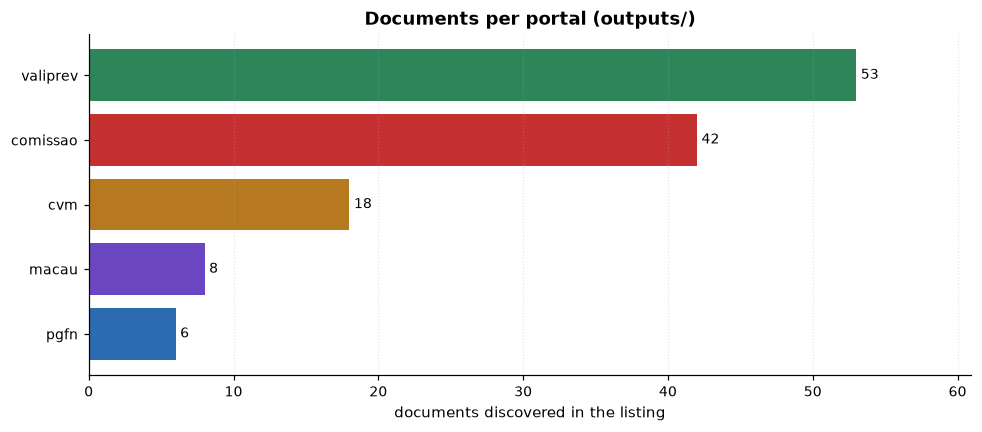

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
order = per_site.sort_values("documents")
bars = ax.barh(
    [d.short_site(s) for s in order.index],
    order["documents"].to_numpy(dtype=float),
    color=d.colors_for(order.index),
)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("documents discovered in the listing")
ax.set_title("Documents per portal (outputs/)")
ax.set_xlim(0, order["documents"].max() * 1.15)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 2 · How complete is the metadata?

A portal that publishes neither size nor date (`comissaodaverdade`,
`macau` in the captured slice, `pgfn`) is the hard case for this crawler: it can
still mirror the documents, but it cannot tell a re-publication from a new file
without downloading it. This is the coverage the `--refresh` / `--no-range-probe`
notes in the README are about.

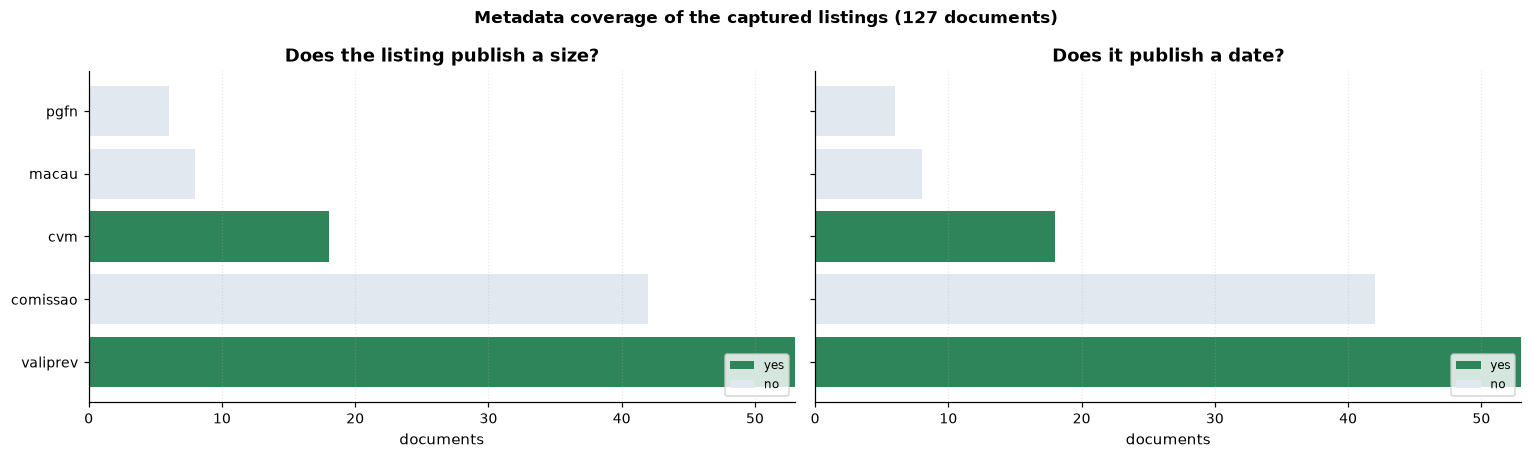

size published for 71/127 documents, date published for 71/127


In [5]:
cov = pd.DataFrame(
    {
        "size published": inv.groupby("site")["size"].count(),
        "date published": inv.groupby("site")["mtime"].count(),
        "documents": inv.groupby("site")["url"].count(),
    }
).fillna(0)
cov["size missing"] = cov["documents"] - cov["size published"]
cov["date missing"] = cov["documents"] - cov["date published"]
cov = cov.loc[per_site.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (have, miss, title) in zip(
    axes,
    (
        ("size published", "size missing", "Does the listing publish a size?"),
        ("date published", "date missing", "Does it publish a date?"),
    ),
):
    y = range(len(cov))
    ax.barh(y, cov[have].to_numpy(dtype=float), color="#2f855a", label="yes")
    ax.barh(
        y,
        cov[miss].to_numpy(dtype=float),
        left=cov[have].to_numpy(dtype=float),
        color="#e2e8f0",
        label="no",
    )
    ax.set_yticks(list(y))
    ax.set_yticklabels([d.short_site(s) for s in cov.index], fontsize=9)
    ax.set_xlabel("documents")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(axis="y", visible=False)

fig.suptitle("Metadata coverage of the captured listings (127 documents)", fontweight="bold")
fig.tight_layout()
plt.show()

print(
    f"size published for {int(cov['size published'].sum())}/{int(cov['documents'].sum())} documents, "
    f"date published for {int(cov['date published'].sum())}/{int(cov['documents'].sum())}"
)

## 3 · How big are the published documents?

Only two portals publish sizes (CVM and Valiprev), so the distribution below is
drawn from those 71 documents. Note the very different scales: the CVM datasets
are multi-MiB archives, the Valiprev certificates are sub-MiB PDFs.

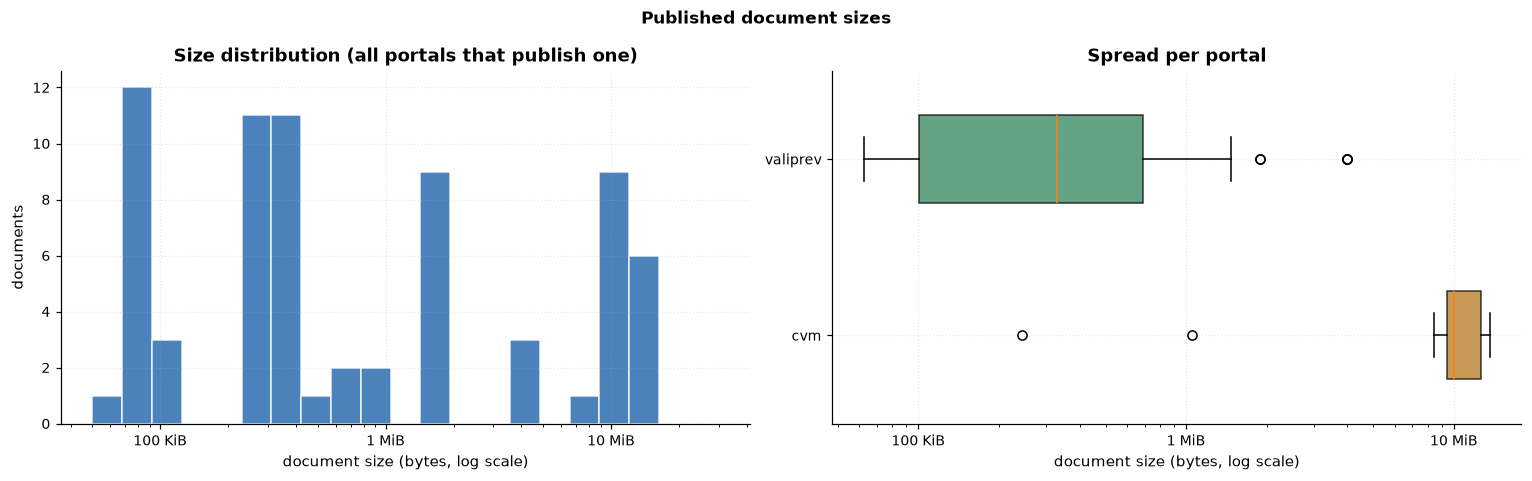

,count,mean (human),median (human),min,max
site,,,,,
dados.cvm.gov.br,18.0,9.5 MiB,9.5 MiB,243712.0,13631488.0
valiprev.sp.gov.br,53.0,679.5 KiB,321.0 KiB,62464.0,3984588.0


In [6]:
sized = inv[inv["size"].notna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

bins = np.logspace(np.log10(5e4), np.log10(3e7), 22)
axes[0].hist(sized["size"], bins=bins, color="#2b6cb0", alpha=0.85, edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_xlabel("document size (bytes, log scale)")
axes[0].set_ylabel("documents")
axes[0].set_title("Size distribution (all portals that publish one)")
axes[0].set_xticks([10**5, 10**6, 10**7])
axes[0].set_xticklabels(["100 KiB", "1 MiB", "10 MiB"])

box_sites = [s for s in sized["site"].unique()]
data = [sized.loc[sized["site"] == s, "size"].to_numpy(dtype=float) for s in box_sites]
_box_kwargs = dict(patch_artist=True, widths=0.5, showfliers=True)
try:  # matplotlib >= 3.10
    bp = axes[1].boxplot(data, orientation="horizontal", **_box_kwargs)
except TypeError:  # older matplotlib
    bp = axes[1].boxplot(data, vert=False, **_box_kwargs)
for patch, site in zip(bp["boxes"], box_sites):
    patch.set_facecolor(d.colors_for([site])[0])
    patch.set_alpha(0.75)
axes[1].set_yticklabels([d.short_site(s) for s in box_sites])
axes[1].set_xscale("log")
axes[1].set_xlabel("document size (bytes, log scale)")
axes[1].set_title("Spread per portal")
axes[1].set_xticks([10**5, 10**6, 10**7])
axes[1].set_xticklabels(["100 KiB", "1 MiB", "10 MiB"])

fig.suptitle("Published document sizes", fontweight="bold")
fig.tight_layout()
plt.show()

desc = sized.groupby("site")["size"].describe()
desc["mean (human)"] = sized.groupby("site")["size"].mean().map(d.human_bytes)
desc["median (human)"] = sized.groupby("site")["size"].median().map(d.human_bytes)
display(desc[["count", "mean (human)", "median (human)", "min", "max"]])

## 3b · How precise are the published sizes?

Apache-style listings publish **rounded** size strings — `8M`, `3.8M`, `387K` —
and `scraper.py` parses them into exact-looking byte counts (`9M` → 9 437 184).
That matters a lot here: two completely different files share a recorded size
whenever they round to the same string, and a 1 MiB bucket is very wide.

(`outputs-replica/` sizes are real `Content-Length` bytes and *are* exact — this
section is about the published sizes in `outputs/` only.)

granularity,rounded to ≤ 1 KiB,rounded to ≤ 1 MiB,exact bytes
site,,,
dados.cvm.gov.br,1,17,0
valiprev.sp.gov.br,41,0,12


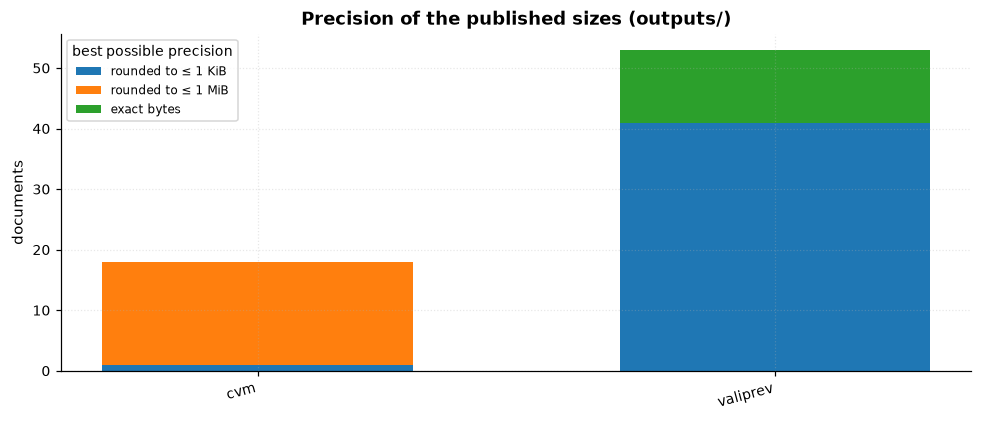

cvm        17/18  sizes rounded to 1 MiB or coarser
valiprev    0/53  sizes rounded to 1 MiB or coarser


In [7]:
gran = sized.assign(
    granularity=sized["size"].map(lambda v: d.size_granularity(v)[1]),
    step=sized["size"].map(lambda v: d.size_granularity(v)[0]),
)
tab = pd.crosstab(gran["site"], gran["granularity"])
tab = tab.reindex(columns=sorted(tab.columns, key=lambda c: (c == "exact bytes", c)))
display(tab)

fig, ax = plt.subplots(figsize=(9, 3.9))
bottom = None
for col in tab.columns:
    vals = tab[col].to_numpy(dtype=float)
    ax.bar(range(len(tab)), vals, bottom=bottom, label=col, width=0.6)
    bottom = vals if bottom is None else bottom + vals
ax.set_xticks(range(len(tab)))
ax.set_xticklabels([d.short_site(s) for s in tab.index], rotation=15, ha="right")
ax.set_ylabel("documents")
ax.set_title("Precision of the published sizes (outputs/)")
ax.legend(fontsize=8, title="best possible precision")
fig.tight_layout()
plt.show()

for site, row in tab.iterrows():
    coarse = sum(row.get(k, 0) for k in ("rounded to \u2264 1 MiB", "rounded to \u2264 1 GiB"))
    print(f"{d.short_site(site):<10} {int(coarse):>2}/{int(row.sum()):<3} sizes rounded to 1 MiB or coarser")

## 4 · What kinds of files are out there?

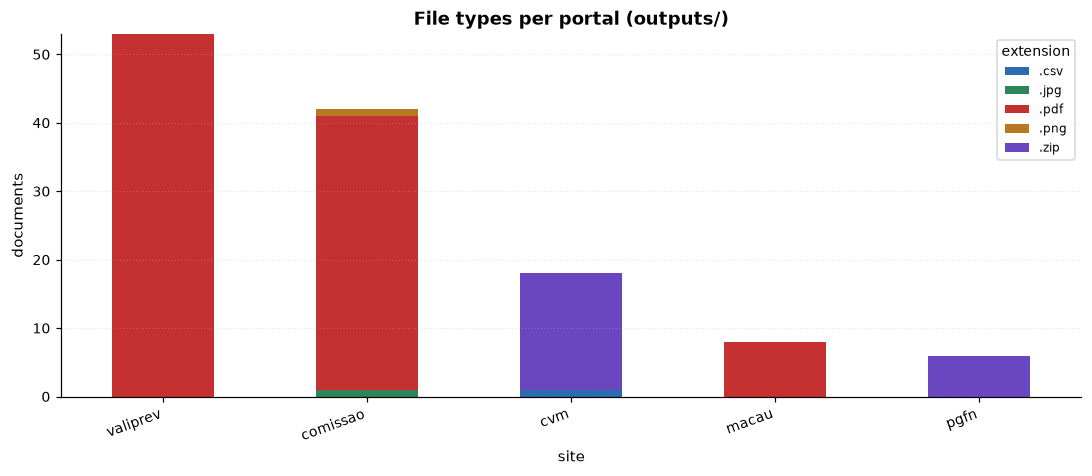

,documents,share
extension,,
.pdf,101,79.5%
.zip,23,18.1%
.jpg,1,0.8%
.png,1,0.8%
.csv,1,0.8%


In [8]:
mix = pd.crosstab(inv["site"], inv["ext"])
mix = mix.loc[per_site.index]
ax = mix.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 4.4),
    color=["#2b6cb0", "#2f855a", "#c53030", "#b7791f", "#6b46c1"],
)
ax.set_xticklabels([d.short_site(s) for s in mix.index], rotation=20, ha="right")
ax.set_ylabel("documents")
ax.set_title("File types per portal (outputs/)")
ax.legend(title="extension", fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

tot = inv["ext"].value_counts().rename_axis("extension").to_frame("documents")
tot["share"] = (tot["documents"] / tot["documents"].sum() * 100).round(1).astype(str) + "%"
display(tot)

## 5 · When were the documents published?

Publication dates exist for CVM (18) and Valiprev (53). Months with no
publication are shown as zero, so the gaps are real gaps in what the portals
published — not missing data.

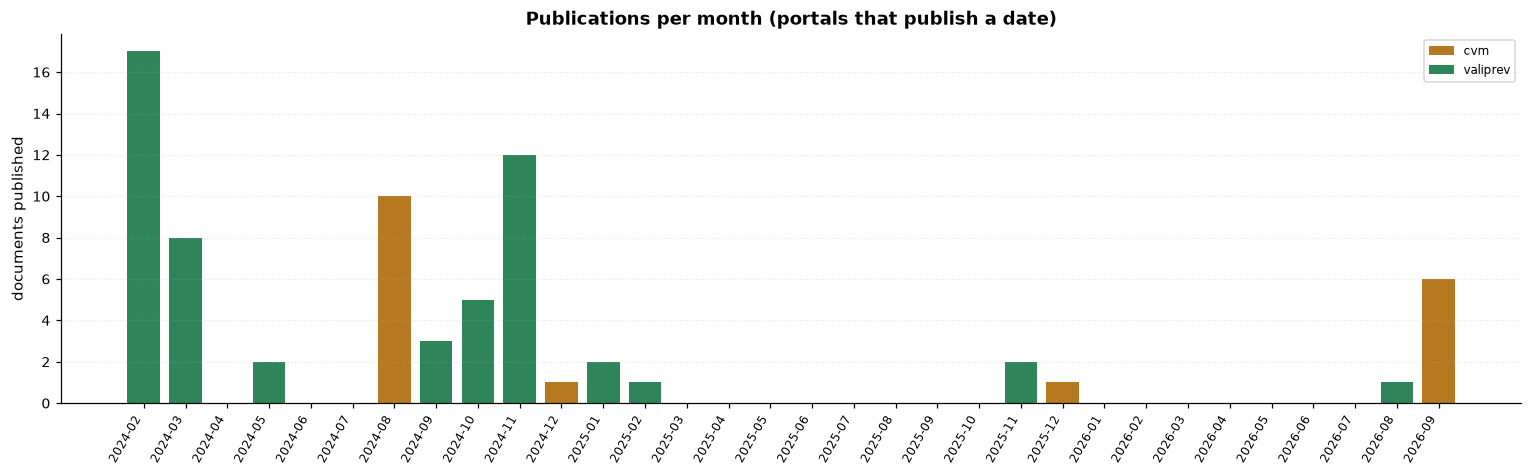

71 dated documents spanning 2024-02 … 2026-09


In [9]:
dated = inv[inv["mtime"].notna()].copy()
dated["month"] = dated["mtime"].dt.tz_convert(None).dt.to_period("M")

grid = (
    dated.pivot_table(index="month", columns="site", values="url", aggfunc="count")
    .reindex(pd.period_range(dated["month"].min(), dated["month"].max(), freq="M"))
    .fillna(0)
)
grid.index = [str(p) for p in grid.index]

fig, ax = plt.subplots(figsize=(14, 4.4))
bottom = None
for site in grid.columns:
    vals = grid[site].to_numpy(dtype=float)
    ax.bar(grid.index, vals, bottom=bottom, label=d.short_site(site), color=d.colors_for([site])[0], width=0.78)
    bottom = vals if bottom is None else bottom + vals
ax.set_ylabel("documents published")
ax.set_title("Publications per month (portals that publish a date)")
ax.legend(fontsize=8)
every = max(1, len(grid) // 24)
ax.set_xticks(range(0, len(grid), every))
ax.set_xticklabels([grid.index[i] for i in range(0, len(grid), every)], rotation=60, ha="right", fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print(f"{len(dated)} dated documents spanning {grid.index[0]} … {grid.index[-1]}")

## 6 · The heavyweights

These are the rows that decide whether `--max-file-bytes` or
`--max-total-bytes` is needed for a first full run.

In [10]:
top = (
    inv.dropna(subset=["size"])
    .sort_values("size", ascending=False)
    .head(15)[["site", "name", "size", "remote_mtime"]]
    .reset_index(drop=True)
)
top.insert(0, "#", top.index + 1)
top["size (human)"] = top["size"].map(d.human_bytes)
display(top[["#", "site", "name", "size (human)", "remote_mtime"]].style.hide(axis="index"))

#,site,name,size (human),remote_mtime
1,dados.cvm.gov.br,dfp_cia_aberta_2021.zip,13.0 MiB,2025-12-28T07:30:00Z
2,dados.cvm.gov.br,dfp_cia_aberta_2023.zip,13.0 MiB,2026-09-27T07:30:00Z
3,dados.cvm.gov.br,dfp_cia_aberta_2022.zip,13.0 MiB,2026-09-27T07:35:00Z
4,dados.cvm.gov.br,dfp_cia_aberta_2024.zip,13.0 MiB,2026-09-27T07:25:00Z
5,dados.cvm.gov.br,dfp_cia_aberta_2025.zip,12.0 MiB,2026-09-27T07:19:00Z
6,dados.cvm.gov.br,dfp_cia_aberta_2020.zip,12.0 MiB,2024-12-29T07:27:00Z
7,dados.cvm.gov.br,dfp_cia_aberta_2019.zip,11.0 MiB,2024-08-05T17:27:00Z
8,dados.cvm.gov.br,dfp_cia_aberta_2018.zip,10.0 MiB,2024-08-05T17:30:00Z
9,dados.cvm.gov.br,dfp_cia_aberta_2017.zip,10.0 MiB,2024-08-05T17:33:00Z
10,dados.cvm.gov.br,dfp_cia_aberta_2015.zip,9.0 MiB,2024-08-05T17:39:00Z


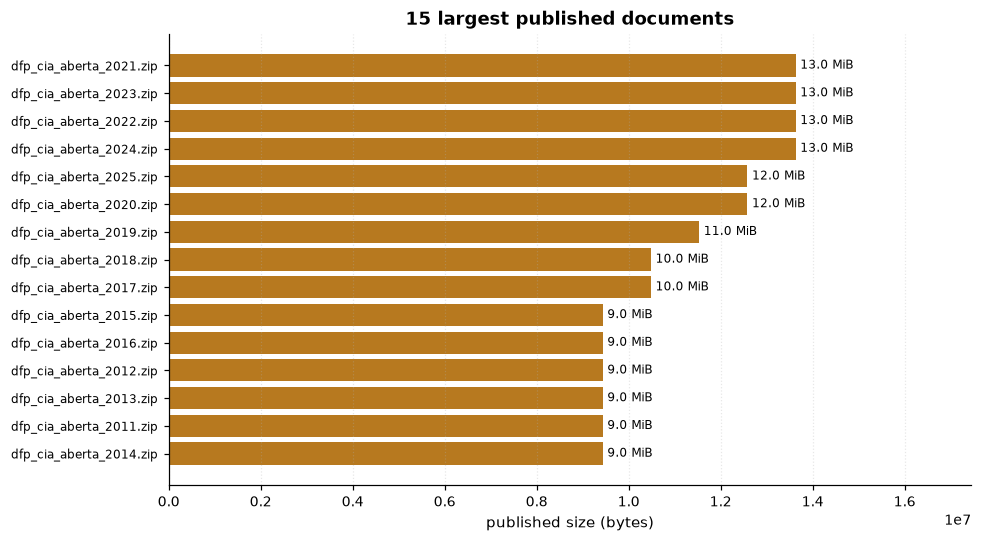

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
t = top.iloc[::-1]
bars = ax.barh(
    [n[:46] + ("…" if len(n) > 46 else "") for n in t["name"]],
    t["size"].to_numpy(dtype=float),
    color=d.colors_for(t["site"]),
)
ax.bar_label(bars, labels=[d.human_bytes(v) for v in t["size"]], padding=3, fontsize=8)
ax.set_xlabel("published size (bytes)")
ax.set_title("15 largest published documents")
ax.set_xlim(0, t["size"].max() * 1.28)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

## Caveats worth carrying into any conclusion

* **56 of the 127 rows have no size** and 56 have no date, because those portals
  publish neither. Every size/timeline chart above is therefore about the 71
  documents from CVM and Valiprev only.
* **The sizes themselves are rounded**, not exact: CVM publishes whole MiB
  (`9M`), Valiprev publishes KiB or bytes (`387K`). Read the size distribution as
  coarse, and never treat two equal sizes in `outputs/` as evidence that two
  documents are the same file — see notebook 03.
* **Nothing here is byte-verified.** `sha256` is empty in every row — this tree
  never downloaded a payload, so the sizes are what the *listing said*.
* `geofiles.caxias.rs.gov.br` is absent: the host could not be read from the
  sandbox that produced this checkout.